# Solar filament instance segmentation: reproducible pipeline

Solar Filament Segmentation Challenge 2026 (MAGFiLO, GONG H-alpha full-disk images, 2048 x 2048 px).

This notebook loads the weights stored in this repository, runs the complete inference pipeline on test images, shows every stage, and writes a submission file. It also reports the out-of-fold validation numbers that the design decisions rest on. Nothing is trained here.

**Pipeline (version 7)**

| Stage | What it does |
|---|---|
| 1. Proposals | Two YOLO11s-seg detectors, at 1024 px and 1536 px, propose filament boxes (confidence 0.05 or more) |
| 2. Crop refinement | A box-seeded U-Net segments each box in its own crop. ResNet18 at 256 px and ResNet34 at 384 px are averaged for the 1024 px detector, ResNet18 at 256 px for the 1536 px detector. Four flips each |
| 3. Paste | All candidates are pasted in detector-score order. A pixel belongs to the first candidate that claims it, so instances never overlap |
| 4. Selection | A gradient-boosted model predicts each instance's expected matched IoU over annotators. Instances at or below 0.24 are dropped |
| 5. Stage 2 | Each kept instance is segmented again in a crop aligned with its long axis, with its neighbours and a dense probability map as context. Five ResNet34 U-Net fold models, four flips |

**Inputs.** `WEIGHTS` holds the twelve files listed in `weights/MANIFEST.json` (1.4 GB, stored with Git LFS).

`DATA` is the competition folder. When it is absent, the three test images in `demo_images/` are used, so the notebook runs from a fresh clone. Only the training split of the competition data was used for training; no external labels.

In [1]:
from pathlib import Path
import json, sys, time, csv, warnings
warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

WEIGHTS = ROOT / "weights"                       # weight files of this repository (Git LFS)
DATA = ROOT / "MAGFiLO_1.0_Kaggle_2026"          # competition data; optional, see above
REFERENCE = ROOT / "submission.csv"              # the file submitted to Kaggle
N_DEMO = 3          # images processed in the walkthrough below
RUN_FULL = False    # True: predict all 180 test images here (needs DATA; about 4 minutes on a GPU, 2.5 hours on a CPU)

import cv2, numpy as np, torch
import matplotlib.pyplot as plt
from solar_filament.pipeline import FilamentPipeline
from solar_filament.rle import decode_mask, encode_mask

manifest = json.loads((WEIGHTS / "MANIFEST.json").read_text())
short = [k for k, v in manifest.items() if not (WEIGHTS / k).is_file() or (WEIGHTS / k).stat().st_size != v["bytes"]]
assert not short, f"weight files missing or still Git LFS pointers (run `git lfs pull`): {short}"
print(f"{len(manifest)} weight files, {sum(v['bytes'] for v in manifest.values()) / 2**20:.0f} MB")
pipe = FilamentPipeline(WEIGHTS)                 # the version follows from the weight files present
VERSION = pipe.version
print("version:", VERSION, "| device:", pipe.device)

12 weight files, 1409 MB


version: v7 | device: cuda


## 1. One image, stage by stage

The four panels show the input, the dense probability map (used as context in stage 2), the instances after selection (stage 1), and the final instances after stage 2.

20110120105534Ch: 7 + 6 candidates, 2 kept, 2 final, 1.5 s


20110130110334Ch: 3 + 3 candidates, 1 kept, 1 final, 0.5 s


20110214175414Mh: 9 + 14 candidates, 4 kept, 4 final, 0.7 s


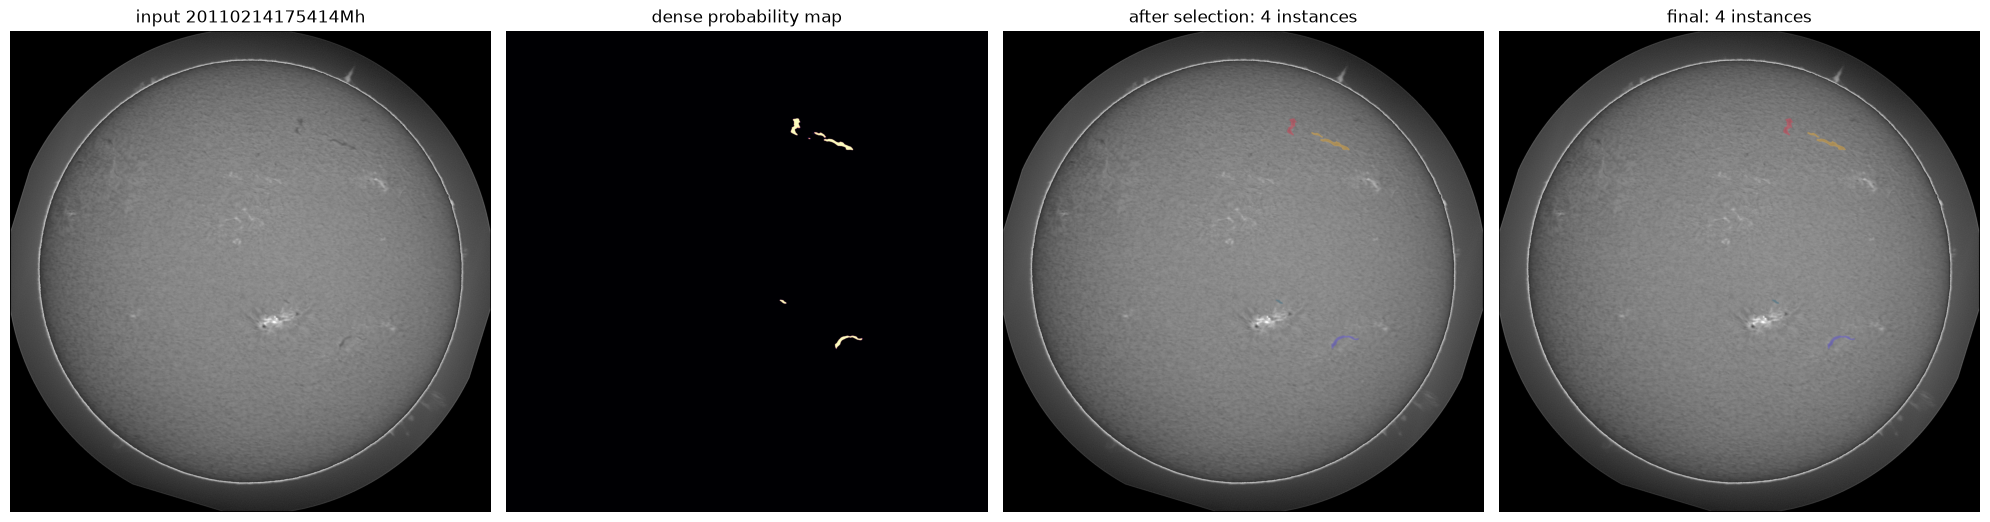

In [2]:
test_images = sorted((DATA / "test" / "test_images").glob("*.jp*g")) or sorted((ROOT / "demo_images").glob("*.jp*g"))
demo = test_images[:N_DEMO]

def colour(labels):
    rng = np.random.default_rng(3)
    lut = np.vstack([[0, 0, 0], rng.integers(70, 255, size=(int(labels.max()) + 1, 3))]).astype(np.uint8)
    return lut[labels]

def overlay(gray, labels, alpha=0.55):
    rgb = np.repeat(gray[:, :, None], 3, axis=2).astype(np.float32)
    m = labels > 0
    rgb[m] = (1 - alpha) * rgb[m] + alpha * colour(labels)[m]
    return rgb.astype(np.uint8)

results = {}
for p in demo:
    t0 = time.time()
    gray = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    labels, stages = pipe.predict(gray, return_stages=True)
    results[p.stem] = (gray, labels, stages)
    print(f"{p.stem}: {stages['candidates'][0]} + {stages['candidates'][1]} candidates, "
          f"{int(stages['stage1'].max())} kept, {int(labels.max())} final, {time.time() - t0:.1f} s")

stem = max(results, key=lambda s: int(results[s][1].max()))   # the demo image with most filaments
gray, labels, stages = results[stem]
fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))
ax[0].imshow(gray, cmap="gray"); ax[0].set_title(f"input {stem}")
ax[1].imshow(stages["dense"], cmap="magma"); ax[1].set_title("dense probability map")
ax[2].imshow(overlay(gray, stages["stage1"])); ax[2].set_title(f"after selection: {int(stages['stage1'].max())} instances")
ax[3].imshow(overlay(gray, labels)); ax[3].set_title(f"final: {int(labels.max())} instances")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. What stage 2 changes

Each row is one filament: the image crop, the mask after selection (cyan), and the final mask (yellow). Stage 2 mostly adjusts the outline and the ends of a filament; it never moves an instance.

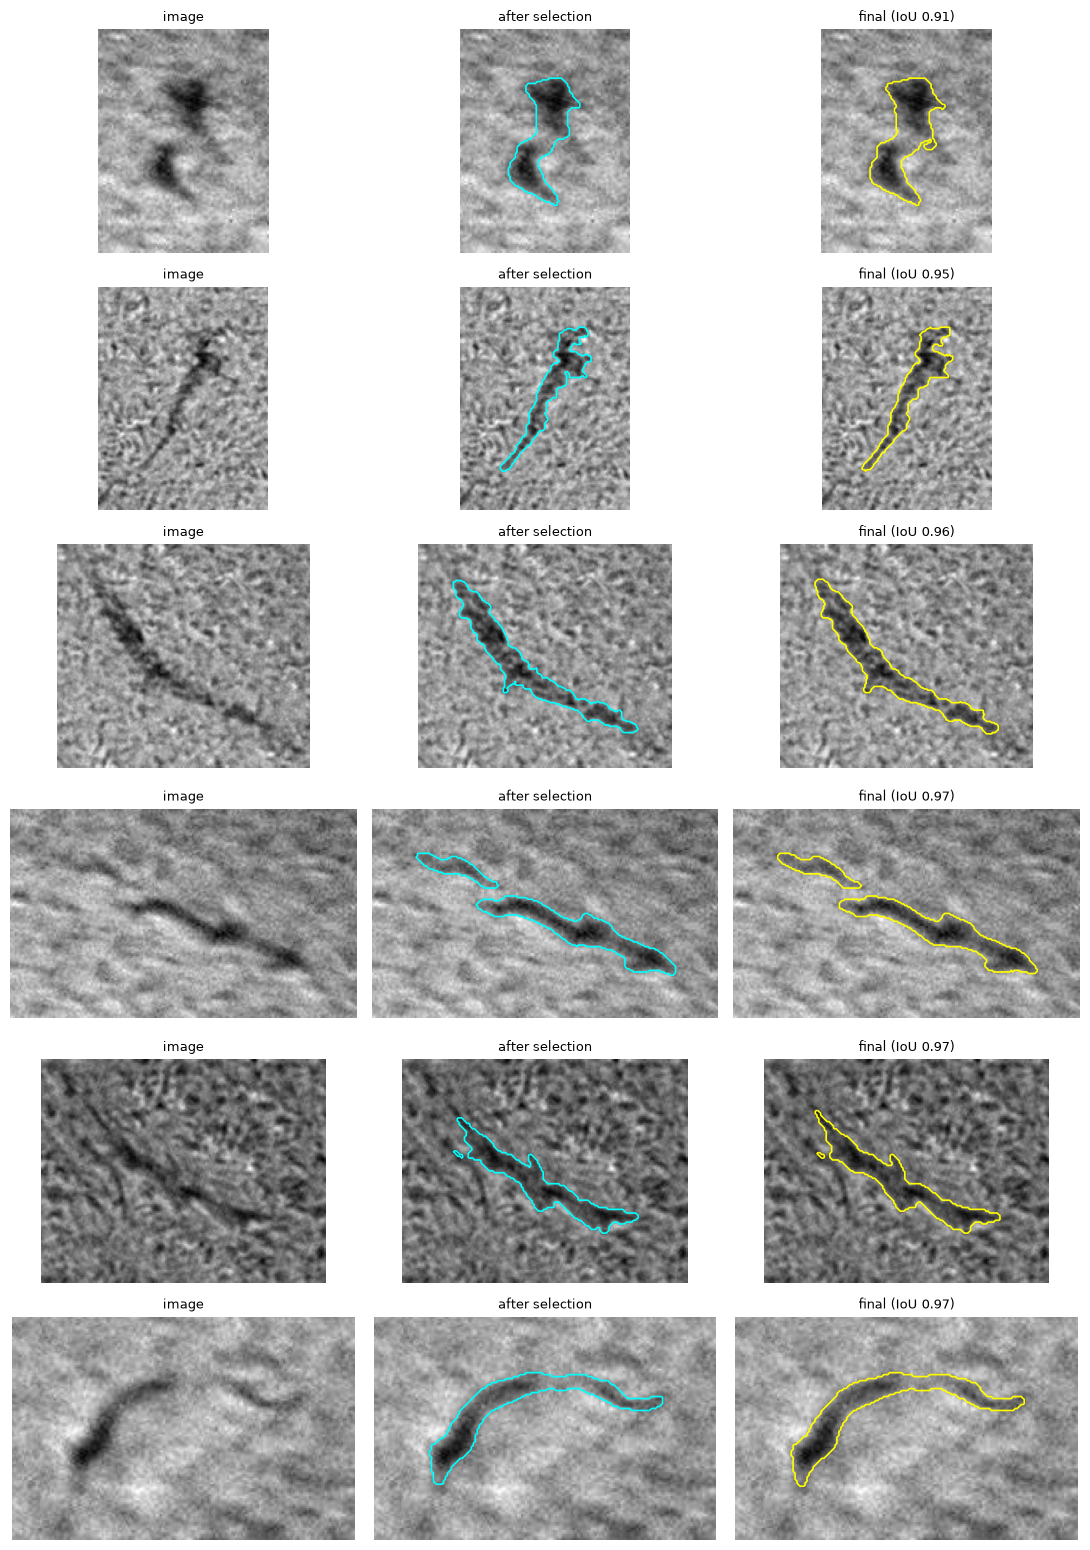

7 instances in 3 images; median IoU between the two masks 0.965


In [3]:
def crop_box(mask, pad=28, size=2048):
    ys, xs = np.nonzero(mask)
    return max(0, ys.min() - pad), min(size, ys.max() + pad), max(0, xs.min() - pad), min(size, xs.max() + pad)

rows = []
for stem, (gray, labels, stages) in results.items():
    s1 = stages["stage1"]
    for i in range(1, int(s1.max()) + 1):
        a = s1 == i
        if not a.any():
            continue
        over = np.bincount(labels[a], minlength=int(labels.max()) + 1); over[0] = 0
        j = int(over.argmax())
        b = labels == j if over[j] else np.zeros_like(a)
        iou = (a & b).sum() / max(1, (a | b).sum())
        rows.append((iou, stem, a, b))
rows.sort(key=lambda r: r[0])
show = rows[:6]
fig, ax = plt.subplots(len(show), 3, figsize=(11, 2.6 * len(show)))
for r, (iou, stem, a, b) in enumerate(show):
    gray = results[stem][0]
    y0, y1, x0, x1 = crop_box(a | b)
    for c, (mask, col, name) in enumerate([(None, None, "image"), (a, "cyan", "after selection"), (b, "yellow", f"final (IoU {iou:.2f})")]):
        ax[r, c].imshow(gray[y0:y1, x0:x1], cmap="gray")
        if mask is not None and mask.any():
            ax[r, c].contour(mask[y0:y1, x0:x1], levels=[0.5], colors=col, linewidths=1.2)
        ax[r, c].set_title(name, fontsize=9); ax[r, c].axis("off")
plt.tight_layout(); plt.show()
print(f"{len(rows)} instances in {len(results)} images; median IoU between the two masks {np.median([r[0] for r in rows]):.3f}")

## 3. Agreement with the submitted file

The masks computed here are compared with the rows of the submitted CSV for the same images. The submitted file was produced on a GPU in half precision. On a GPU this pipeline reproduces it almost exactly (section 4). On a CPU the detector boxes and probabilities differ in the last digits, which moves some outlines by a pixel or two, so the best IoU per filament is typically 0.95 to 0.99 and the instance counts are the same.

In [4]:
csv.field_size_limit(10 ** 9)
ref = {}
with open(REFERENCE) as fh:
    for r in csv.DictReader(fh):
        ref.setdefault(r["filament_id"].rsplit("_", 1)[0], []).append(r["segmentation_rle"])
for stem, (gray, labels, _) in results.items():
    n = int(labels.max()); area = np.bincount(labels.ravel(), minlength=n + 1).astype(float)
    best = []
    for rle in ref.get(stem, []):
        g = decode_mask(rle, 2048, 2048)
        inter = np.bincount(labels[g], minlength=n + 1).astype(float)
        iou = inter / (area + g.sum() - inter + 1e-9); iou[0] = 0
        best.append(iou.max() if n else 0.0)
    print(f"{stem}: {n} instances here, {len(best)} in the submitted file, mean best IoU {np.mean(best) if best else 1:.4f}")

20110120105534Ch: 2 instances here, 2 in the submitted file, mean best IoU 0.9996
20110130110334Ch: 1 instances here, 1 in the submitted file, mean best IoU 1.0000


20110214175414Mh: 4 instances here, 4 in the submitted file, mean best IoU 0.9985


## 4. Full test set and submission file

`scripts/predict.py` runs the same `FilamentPipeline` over a folder and writes the CSV. The full run was executed on one GPU and compared with the submitted file; its log is `results/predict/repro/summary.json`. Set `RUN_FULL = True` above to repeat it here.

In [5]:
if RUN_FULL:
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "scripts" / "predict.py"), f"--images={DATA / 'test' / 'test_images'}",
                    f"--weights={WEIGHTS}", f"--out={ROOT / 'submission.csv'}", f"--compare={REFERENCE}",
                    "--tag=notebook_full"], check=True)
    s = json.loads((ROOT / "results" / "predict" / "notebook_full" / "summary.json").read_text())
else:
    s = json.loads((ROOT / "results" / "predict" / "repro" / "summary.json").read_text())
c = s["compare"]
print(f"device {s['device']}, {s['images']} images, {s['rows']} rows, {s['seconds_per_image']} s per image")
print(f"submitted rows {c['reference_rows']}: matched {c['matched_iou_gt_0.5']}, identical {c['identical_masks']}, "
      f"mean IoU of matched {c['mean_iou_of_matched']:.4f}, images with the same count {c['images_with_same_count']}")

device cuda, 180 images, 1216 rows, 0.98 s per image
submitted rows 1214: matched 1214, identical 1091, mean IoU of matched 0.9995, images with the same count 178


## 5. Validation

All numbers below are out of fold: the 707 training images are split into five grouped folds, and every image is predicted by detectors, refiners, selector and stage-2 models that never saw it. Scoring follows the competition: every annotator view of an image is scored separately and pooled. A prediction matches a label when their IoU exceeds 0.5.

images 707, annotator views 1154
PQ 0.4626 = SQ 0.6860 x RQ 0.6744   (TP 5295, FP 2210, FN 2904)
mean Dice per view 0.6551, median 0.6879, pooled 0.6858
mean IoU per view 0.5054; pixel precision 0.728, recall 0.648
matched pairs: mean IoU 0.686, mean Dice 0.811
one label holding several predictions: 1.4% of labels; one prediction holding several labels: 2.5% of predictions


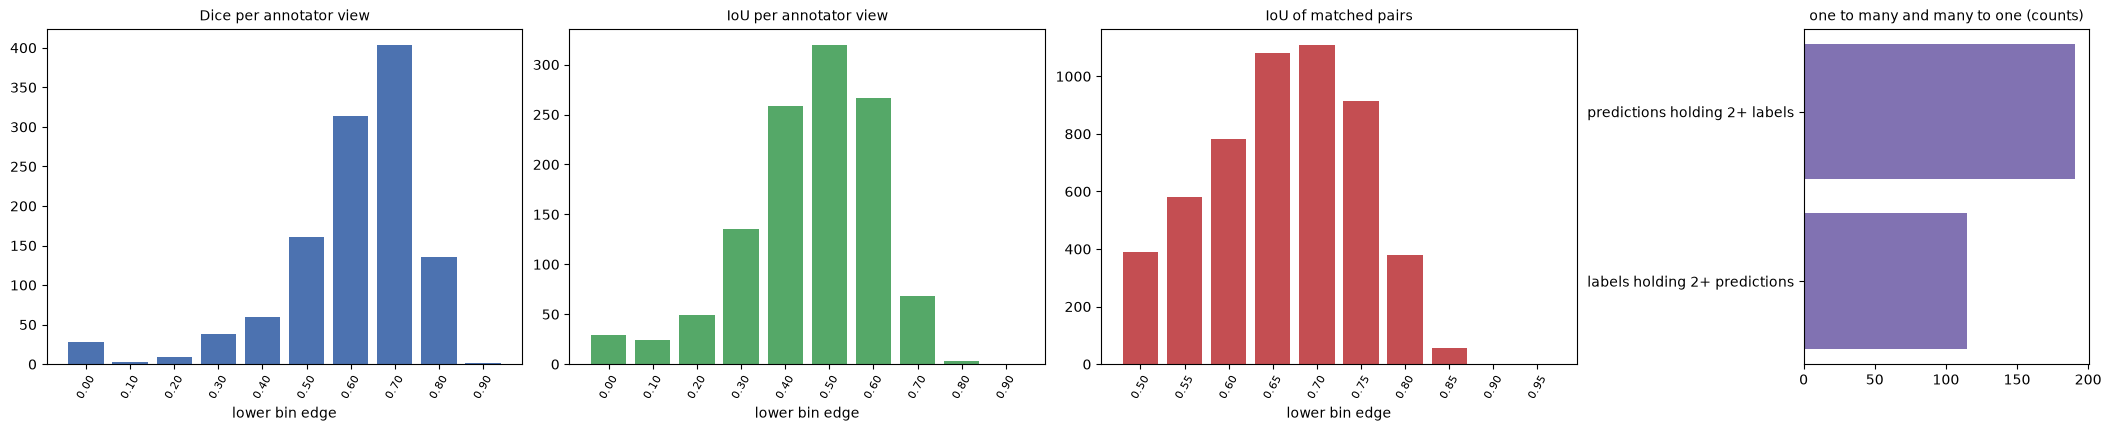

In [6]:
rub = json.loads((ROOT / "results" / "rubric_metrics" / "summary.json").read_text())
sel = rub["selected"]
print(f"images {rub['images']}, annotator views {sel['views']}")
print(f"PQ {sel['pq']:.4f} = SQ {sel['sq']:.4f} x RQ {sel['rq']:.4f}   (TP {sel['tp']}, FP {sel['fp']}, FN {sel['fn']})")
print(f"mean Dice per view {sel['mean_dice_per_view']:.4f}, median {sel['median_dice_per_view']:.4f}, pooled {sel['global_dice']:.4f}")
print(f"mean IoU per view {sel['mean_iou_per_view']:.4f}; pixel precision {sel['pixel_precision']:.3f}, recall {sel['pixel_recall']:.3f}")
print(f"matched pairs: mean IoU {sel['matched_pair_iou_mean']:.3f}, mean Dice {sel['matched_pair_dice_mean']:.3f}")
print(f"one label holding several predictions: {100 * sel['one_to_many_share_of_gt']:.1f}% of labels; "
      f"one prediction holding several labels: {100 * sel['many_to_one_share_of_pred']:.1f}% of predictions")

def bars(ax, hist, title, colour):
    keys = list(hist); ax.bar(range(len(keys)), [hist[k] for k in keys], color=colour)
    ax.set_xticks(range(len(keys))); ax.set_xticklabels([k.split("-")[0] for k in keys], rotation=60, fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("lower bin edge")

fig, ax = plt.subplots(1, 4, figsize=(21, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 0.6]}, constrained_layout=True)
bars(ax[0], sel["dice_per_view_hist"], "Dice per annotator view", "#4c72b0")
bars(ax[1], sel["iou_per_view_hist"], "IoU per annotator view", "#55a868")
bars(ax[2], sel["matched_pair_iou_hist"], "IoU of matched pairs", "#c44e52")
rel = {"labels holding 2+ predictions": sum(v for k, v in sel["gt_predictions_inside_counts"].items() if int(k) >= 2),
       "predictions holding 2+ labels": sum(v for k, v in sel["pred_labels_inside_counts"].items() if int(k) >= 2)}
ax[3].barh(list(rel), list(rel.values()), color="#8172b2"); ax[3].set_title("one to many and many to one (counts)", fontsize=10)
plt.show()

The Dice above is the foreground Dice of the union of predicted instances against the union of one annotator's labels, per view. `tests/test_rubric_dice.py` checks that it equals `torchmetrics.segmentation.DiceScore`.

**How the pipeline grew (out-of-fold PQ on the same 707 images)**

| Version | Change | Out-of-fold PQ | Public board |
|---|---|---|---|
| v5 | 1024 px detector, two averaged refiners, learned selector | 0.4583 | 0.40 |
| v6 | plus candidates of a 1536 px detector | 0.4596 | 0.41 |
| v7 | plus stage 2 | 0.4626 | 0.41 |
| v9 | stage 2 replaced by fine-tuned SAM 2.1 (small and base-plus) | 0.4695 | 0.41 |
| v10 | SAM 2.1 base-plus and large | 0.4704 | 0.41 |
| v11 | v10 masks, kept when the mean of selector value and SAM quality score exceeds 0.24 | 0.4724 | 0.41 |

This repository holds version 7, the last row before SAM 2.1 was introduced. It is the faster configuration (about 1.2 s per image on one GPU against about 11 s for v11).

For reference, one annotator scored against another reaches a PQ of 0.340 on the images with several annotators. `report/report.pdf` is the technical report; `experiments/REPORT.md` is the long form with the experiments that were rejected and the error analysis.